(Q1.)In a reactor A+B = C reaches equilibrium. Initial concentration are [A]o = 1.5 , [B]o= 1.0 and  [C]o = 0mol/L .If x mol /L of C is formed ,Kc =x/((1.5 -x)(1-x)), which rearanges to quadratic equation Kc.xsquare - (2.5Kc +1).x + 1.5Kc =0 Write a python that :
(a) Reads Kc using input(), prints the data type of raw input ad of converted value and shows a clear message (no crash) if the text is not a number or if Kc <_0; 
(b) finds a,b,c the discriminant and both roots
(c) selects the physically meaningful root(0<_ x <_1,because B is limiting);
(d) prints equilibrium [A],[B],[C] (3 DECIMALS ) and the conversion of the limiting reactant B = x / [B]o * 100 (%);
(e) classifies the conversion using if/elif/else:_>70%"HIGH",_> 40% "MODERATE", otherwise "LOW ".

In [4]:
import math

raw_kc = input("Enter Kc: ")
print("Raw input type:", type(raw_kc).__name__)

try:
    kc = float(raw_kc)
except ValueError:
    print("Error: Kc must be a valid number.")
else:
    print("Converted value type:", type(kc).__name__)

    if not math.isfinite(kc) or kc <= 0:
        print("Error: Kc must be a finite number greater than 0.")
    else:
        # Kc*x^2 - (2.5*Kc + 1)*x + 1.5*Kc = 0
        a = kc
        b = -(2.5 * kc + 1)
        c = 1.5 * kc

        discriminant = b**2 - 4 * a * c
        sqrt_discriminant = math.sqrt(discriminant)

        root1 = (-b + sqrt_discriminant) / (2 * a)
        root2 = (-b - sqrt_discriminant) / (2 * a)

        print(f"a = {a}")
        print(f"b = {b}")
        print(f"c = {c}")
        print(f"Discriminant = {discriminant}")
        print(f"Root 1 = {root1}")
        print(f"Root 2 = {root2}")

        valid_roots = [root for root in (root1, root2) if 0 < root < 1]

        if not valid_roots:
            print("Error: No physically meaningful root was found.")
        else:
            x = valid_roots[0]

            equilibrium_a = 1.5 - x
            equilibrium_b = 1.0 - x
            equilibrium_c = x
            conversion_b = (x / 1.0) * 100

            print(f"\nEquilibrium [A] = {equilibrium_a:.3f} mol/L")
            print(f"Equilibrium [B] = {equilibrium_b:.3f} mol/L")
            print(f"Equilibrium [C] = {equilibrium_c:.3f} mol/L")
            print(f"Conversion of B = {conversion_b:.3f}%")

            if conversion_b > 70:
                classification = "HIGH"
            elif conversion_b > 40:
                classification = "MODERATE"
            else:
                classification = "LOW"

            print("Conversion classification:", classification)

Raw input type: str
Converted value type: float
a = 0.5
b = -2.25
c = 0.75
Discriminant = 3.5625
Root 1 = 4.1374586088176875
Root 2 = 0.36254139118231254

Equilibrium [A] = 1.137 mol/L
Equilibrium [B] = 0.637 mol/L
Equilibrium [C] = 0.363 mol/L
Conversion of B = 36.254%
Conversion classification: LOW


(Q2). Part A .In a batch reactor reactant A is consumed by a first order reaction ,dC/dt = -kC. Use the Euler method :C_new=C_old-k.C_old.delta t .Take Co = 2.5 mol/L, k = 0.04 min-1 , t = 1 min.
(i) using a for loop simulate 12 minutes and print a table  of time (min), concentration(mol/l) and conversion(%).
(ii) using math.exp(),calculate the exact value Coeto the power(-kt) at 12 min and print absolute error pf euler result .
(iii) using while loop repeat simulation until conversion reaches 40% or time reaches 100 min. Print the time needed and final concentration . 
Part B. Distillation-column sample codes such as DIST2026X9Q3 are stored as text. Write a program that reads a code , loops  through each character, and prints the number of digits and sum  of digits . sShow a message for an empty code and for a code with no digits. Test with DIST2026X9Q3, an empty code and ABCDEF.

In [8]:
import math

# Part A: Euler simulation
Co = 2.5       # mol/L
k = 0.04       # min^-1
dt = 1.0       # min
simulation_time = 12

concentration = Co

print("Part A(i): Euler simulation")
print(f"{'Time (min)':>10} {'Concentration (mol/L)':>24} {'Conversion (%)':>18}")

for time in range(simulation_time + 1):
    conversion = (Co - concentration) / Co * 100
    print(f"{time:10d} {concentration:24.4f} {conversion:18.2f}")

    if time < simulation_time:
        concentration = concentration - k * concentration * dt

# Exact concentration and absolute error at 12 minutes
exact_concentration = Co * math.exp(-k * simulation_time)
absolute_error = abs(exact_concentration - concentration)

print(f"\nPart A(ii): Exact concentration at {simulation_time} min = "
      f"{exact_concentration:.4f} mol/L")
print(f"Absolute error of Euler result = {absolute_error:.6f} mol/L")

# Euler simulation until 40% conversion or 100 minutes
concentration = Co
time = 0

while (Co - concentration) / Co * 100 < 40 and time < 100:
    concentration = concentration - k * concentration * dt
    time += dt

print("\nPart A(iii):")
print(f"Time needed = {time:.0f} min")
print(f"Final concentration = {concentration:.4f} mol/L")
print(f"Final conversion = {(Co - concentration) / Co * 100:.2f}%")


# Part B: Count and sum digits in a code
code = input("\nEnter a distillation column code: ")

if code == "":
    print("The code is empty.")
else:
    digit_count = 0
    digit_sum = 0

    for character in code:
        if character in "0123456789":
            digit_count += 1
            digit_sum += int(character)

    if digit_count == 0:
        print("The code contains no digits.")
    else:
        print(f"Number of digits: {digit_count}")
        print(f"Sum of digits: {digit_sum}")
        

Part A(i): Euler simulation
Time (min)    Concentration (mol/L)     Conversion (%)
         0                   2.5000               0.00
         1                   2.4000               4.00
         2                   2.3040               7.84
         3                   2.2118              11.53
         4                   2.1234              15.07
         5                   2.0384              18.46
         6                   1.9569              21.72
         7                   1.8786              24.86
         8                   1.8035              27.86
         9                   1.7313              30.75
        10                   1.6621              33.52
        11                   1.5956              36.18
        12                   1.5318              38.73

Part A(ii): Exact concentration at 12 min = 1.5470 mol/L
Absolute error of Euler result = 0.015184 mol/L

Part A(iii):
Time needed = 13 min
Final concentration = 1.4705 mol/L
Final conversion = 41.18%


(Q3).Part.A . A laboratory has n candidate solvents and wants to test r of them together in a  mixed solvent (order does not matter). Write a recursive function  factorial(n) (remember the base case for 0!) and a function combination (n,r) = n! / (r! (n-r)!) that uses it. Reject invalid input (negative values,r>n).Print the number of possible mixtures fot n = 9,r=3, and show the message for n=6,r=8.

 Part B. During a crystallisation run,samples are taken at times = Fibonacci number *4min. Write an itirative function fib_iter(n) that returns a list of first n Fibonacci numbers(Fo = 0 ,F1 = 1). For n = 10 , check that both functions agree and print  a table :Sample . | Fibonacci tag | Sampling time (min).

In [3]:
def factorial(n):
    if n < 0:
        raise ValueError("Factorial is not defined for negative integers.")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if n < 0 or r < 0 or r > n:
        raise ValueError("Invalid input: require n >= 0 and 0 <= r <= n.")
    return factorial(n) // (factorial(r) * factorial(n - r))


print("Part A:")
print(f"Number of mixtures for n=9, r=3: {combination(9, 3)}")

try:
    print(combination(6, 8))
except ValueError as error:
    print(f"n=6, r=8: {error}")


# Part B: Fibonacci sampling schedule

def fib_iter(n):
    """Return the first n Fibonacci numbers, starting with 0, 1."""
    if n < 0:
        raise ValueError("n must be non-negative.")

    numbers = []
    first, second = 0, 1

    for _ in range(n):
        numbers.append(first)
        first, second = second, first + second

    return numbers


def fib_recursive(index):
    """Return the Fibonacci number at the given zero-based index."""
    if index < 0:
        raise ValueError("index must be non-negative.")
    if index < 2:
        return index
    return fib_recursive(index - 1) + fib_recursive(index - 2)


n = 10
iterative_numbers = fib_iter(n)
recursive_numbers = [fib_recursive(i) for i in range(n)]

print("\nPart B:")
print("Both functions agree:", iterative_numbers == recursive_numbers)
print(f"{'Sample':>6} | {'Fibonacci tag':>13} | {'Sampling time (min)':>19}")

for sample, tag in enumerate(iterative_numbers, start=1):
    print(f"{sample:6} | {tag:13} | {tag * 4:19}")

Part A:
Number of mixtures for n=9, r=3: 84
n=6, r=8: Invalid input: require n >= 0 and 0 <= r <= n.

Part B:
Both functions agree: True
Sample | Fibonacci tag | Sampling time (min)
     1 |             0 |                   0
     2 |             1 |                   4
     3 |             1 |                   4
     4 |             2 |                   8
     5 |             3 |                  12
     6 |             5 |                  20
     7 |             8 |                  32
     8 |            13 |                  52
     9 |            21 |                  84
    10 |            34 |                 136


(Q 4). Consumption of a reactant was studied in a batch reactor with two feed concentration of catalyst. The concentration (mol/L) was recored:Time_min = 0,10,20,30,40,50, Run1_mol_L(low catalyst) = 1.50,1.17,0.91,0.71,0.55,0.43, Run2_mol_L(high catalyst) = 1.50,0.96,0.61,0.39,0.25,0.16
(a) Create  a DataFrame from this table .Save it as kinetics .csv (without the index column ) and as kinetics .json .Read the CSV back and print its shape and data types .
(b) Print the mean and standard  deviation of Run1 and Run2 , and state which run shows more variation. 
(c) Plot both runs on one graph (Time on x-axis) with title ,axis labels with units legends and grid. 
(d) Ethylene gas is compresed slowly in a piston-cylinder at constant temperature : 
Volume_L : 1,2,3,4,5 , Pressure_bar 5.03,2.52,1.65,1.26,1.01.
 Plot pressure vs volume as a scatter plot.
 Calculate k as the mean pf P *V and draw the reference curve P = k/V on the same graph. Add title ,labels with unita and legends.

CSV shape: (6, 3)

CSV data types:
Time_min        int64
Run1_mol_L    float64
Run2_mol_L    float64
dtype: object

Run1_mol_L: mean = 0.8783 mol/L, standard deviation = 0.4024 mol/L

Run2_mol_L: mean = 0.6450 mol/L, standard deviation = 0.5075 mol/L

Run 2 shows more variation (higher standard deviation).

Mean value of P × V, k = 5.022 bar·L


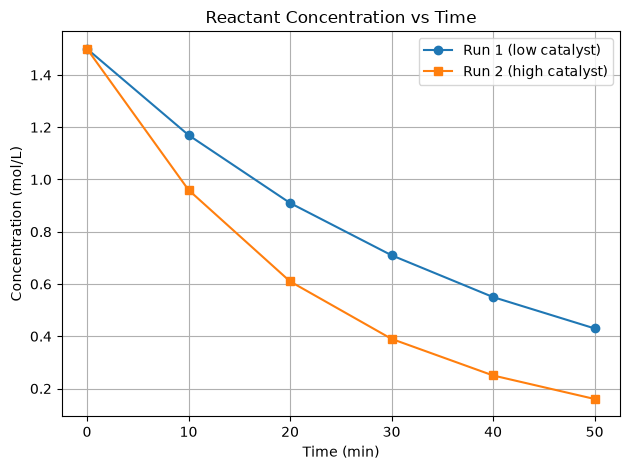

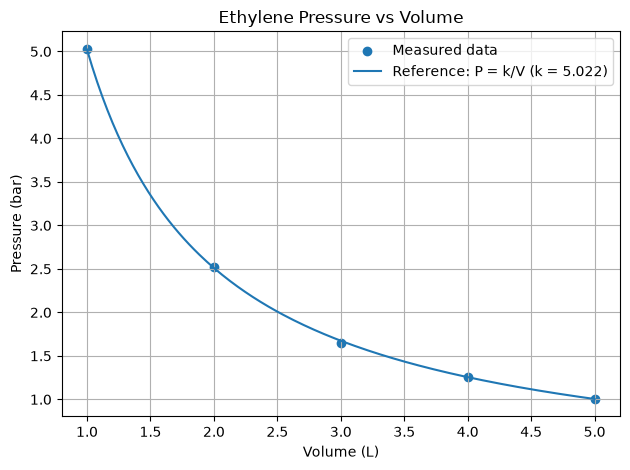

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Part (a): Create, save, and reload the kinetics data
kinetics = pd.DataFrame({
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L": [1.50, 1.17, 0.91, 0.71, 0.55, 0.43],
    "Run2_mol_L": [1.50, 0.96, 0.61, 0.39, 0.25, 0.16],
})

kinetics.to_csv("kinetics.csv", index=False)
kinetics.to_json("kinetics.json", orient="records", indent=2)

kinetics_read = pd.read_csv("kinetics.csv")
print("CSV shape:", kinetics_read.shape)
print("\nCSV data types:")
print(kinetics_read.dtypes)

# Part (b): Mean and sample standard deviation
for run in ["Run1_mol_L", "Run2_mol_L"]:
    print(
        f"\n{run}: mean = {kinetics_read[run].mean():.4f} mol/L, "
        f"standard deviation = {kinetics_read[run].std():.4f} mol/L"
    )

if kinetics_read["Run1_mol_L"].std() > kinetics_read["Run2_mol_L"].std():
    print("\nRun 1 shows more variation (higher standard deviation).")
else:
    print("\nRun 2 shows more variation (higher standard deviation).")

# Part (c): Plot both kinetics runs
plt.figure()
plt.plot(kinetics_read["Time_min"], kinetics_read["Run1_mol_L"],
         marker="o", label="Run 1 (low catalyst)")
plt.plot(kinetics_read["Time_min"], kinetics_read["Run2_mol_L"],
         marker="s", label="Run 2 (high catalyst)")
plt.title("Reactant Concentration vs Time")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()

# Part (d): Ethylene pressure-volume data and reference curve
volume_l = np.array([1, 2, 3, 4, 5], dtype=float)
pressure_bar = np.array([5.03, 2.52, 1.65, 1.26, 1.01])

k = np.mean(pressure_bar * volume_l)
print(f"\nMean value of P × V, k = {k:.3f} bar·L")

volume_curve = np.linspace(volume_l.min(), volume_l.max(), 200)
pressure_curve = k / volume_curve

plt.figure()
plt.scatter(volume_l, pressure_bar, label="Measured data")
plt.plot(volume_curve, pressure_curve, label=f"Reference: P = k/V (k = {k:.3f})")
plt.title("Ethylene Pressure vs Volume")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()